In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from gps_ids import figures
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, f1_score


In [2]:
from gps_ids import protocol, training

EXP = protocol.real_heldout("2d")
r = training.run("XGBoost", EXP)
model = r.model
y_pred = r.y_pred
y_test = EXP.y_test
feature_names = EXP.feature_names


mcc=0.8528  balanced_accuracy=0.9426  f1_macro=0.8842  g_mean=0.9420  accuracy=0.9368  majority_baseline_accuracy=0.7792  accuracy_lift_over_majority=0.1576  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/2D_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [3]:
# Report the model's performance on the test set
print("\nEvaluating the model on the test set...")
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Model Accuracy on Test Set: {accuracy * 100:.2f}%")
print(f"F1 Score: {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Evaluating the model on the test set...
Model Accuracy on Test Set: 93.68%
F1 Score: 0.9405

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     79565
           1       0.76      0.93      0.84      7292
           2       0.69      0.91      0.78      8846
           3       0.91      1.00      0.95      6403

    accuracy                           0.94    102106
   macro avg       0.84      0.94      0.88    102106
weighted avg       0.95      0.94      0.94    102106



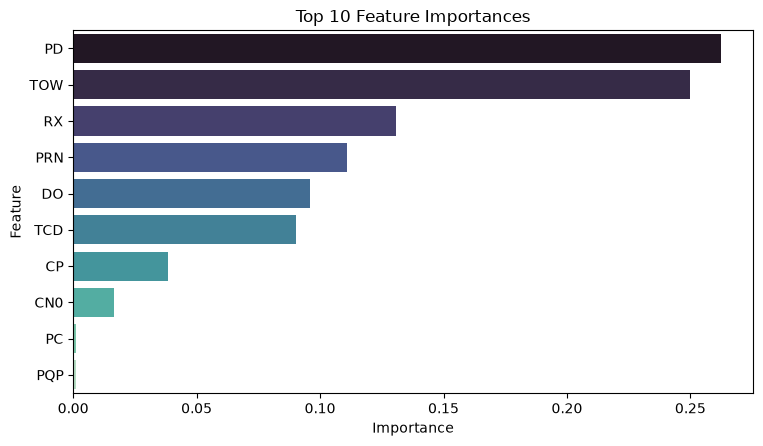

In [4]:
importances = model.feature_importances_

# Create a DataFrame for feature importances
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort by importance descending
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(10),
    x='Importance',
    y='Feature',
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('Top 10 Feature Importances')
plt.tight_layout()
figures.save('feature_importance')
plt.show()

In [5]:
print(feat_imp_df.head(10))

   Feature  Importance
2       PD    0.262359
4      TOW    0.249915
3       RX    0.130871
0      PRN    0.110719
1       DO    0.095883
11     TCD    0.090063
5       CP    0.038509
12     CN0    0.016429
8       PC    0.001165
10     PQP    0.001112


In [6]:
# Seed sweep: the remaining seeds in training.SEEDS, appended to the results CSV.
SWEEP_SEEDS = [s for s in training.SEEDS if s != protocol.SEED]

training.run_seeds("XGBoost", lambda s: protocol.real_heldout("2d", seed=s), seeds=SWEEP_SEEDS)


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


mcc=0.8530  balanced_accuracy=0.9435  f1_macro=0.8848  g_mean=0.9429  accuracy=0.9369  majority_baseline_accuracy=0.7792  accuracy_lift_over_majority=0.1577  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/2D_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


mcc=0.8534  balanced_accuracy=0.9432  f1_macro=0.8849  g_mean=0.9425  accuracy=0.9371  majority_baseline_accuracy=0.7792  accuracy_lift_over_majority=0.1579  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/2D_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


mcc=0.8535  balanced_accuracy=0.9426  f1_macro=0.8844  g_mean=0.9419  accuracy=0.9372  majority_baseline_accuracy=0.7792  accuracy_lift_over_majority=0.1580  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/2D_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


mcc=0.8562  balanced_accuracy=0.9452  f1_macro=0.8871  g_mean=0.9445  accuracy=0.9384  majority_baseline_accuracy=0.7792  accuracy_lift_over_majority=0.1592  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/2D_Results.csv


[{'model': 'XGBoost',
  'dataset': 'GPS_Data_Simplified_2D_Feature_Map.xlsx',
  'family': 'Regular',
  'test_set': 'real_heldout_20pct',
  'seed': 7,
  'n_classes': 4,
  'class_names': 'benign;simple;intermediate;sophisticated',
  'n_train': 408424,
  'n_test': 102106,
  'n_features': 13,
  'mcc': 0.8530388480678264,
  'balanced_accuracy': 0.9435332315033508,
  'f1_macro': 0.8848232919326537,
  'g_mean': 0.9428988893974026,
  'precision_macro': 0.8396322198892453,
  'recall_macro': 0.9435332315033508,
  'accuracy': 0.936908702720702,
  'majority_baseline_accuracy': 0.779239221984996,
  'accuracy_lift_over_majority': 0.15766948073570608,
  'f1_weighted': 0.9405679084344126,
  'is_degenerate': False,
  'n_classes_predicted': 4,
  'min_class_recall': 0.9015374180420529,
  'worst_class': 'intermediate',
  'recall_c0': 0.935750644127443,
  'recall_c1': 0.9385628085573231,
  'recall_c2': 0.9015374180420529,
  'recall_c3': 0.9982820552865844,
  'precision_c0': 0.9997582951753031,
  'precision